In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea
import scipy.stats as stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

# um Warnungen zu ignorieren (auf eigene Gefahr!)
import warnings
warnings.filterwarnings("ignore")

### Laden der Daten

In [2]:
penguins = pd.read_excel('./data/penguinsSmall.xlsx', index_col=0)
display(penguins.head(3))

,Individual ID,Species,Island,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex
0,N1A1,Adelie,Torgersen,2007-11-11,39.1,18.7,181,3750,MALE
1,N1A2,Adelie,Torgersen,2007-11-11,39.5,17.4,186,3800,FEMALE
2,N2A1,Adelie,Torgersen,2007-11-16,40.3,18.0,195,3250,FEMALE


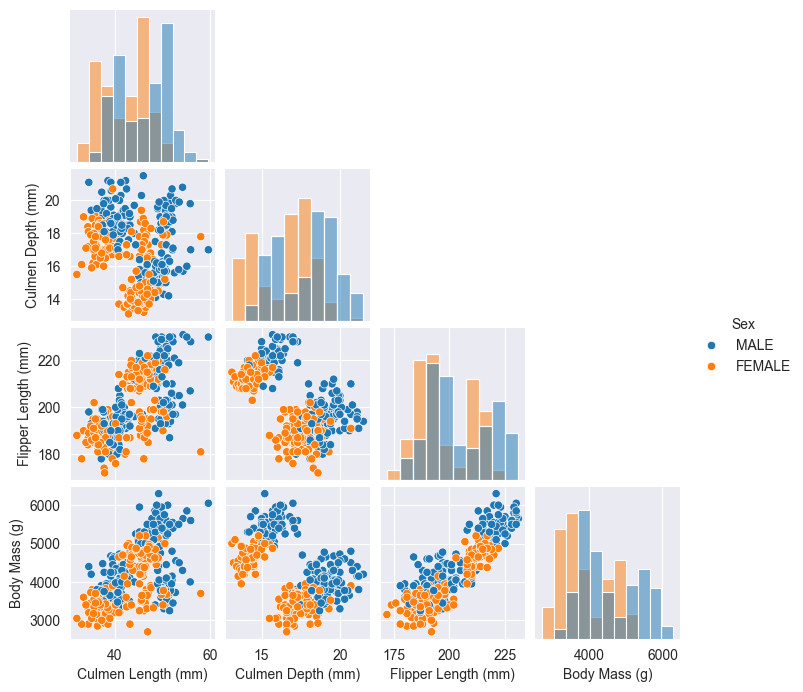

In [3]:
# Übersicht mittels pairplot
sea.pairplot(data=penguins, hue='Sex', corner=True, diag_kind='hist', height=1.75)
plt.show()

Anzahl Beobachtungen im Trainingsdatensatz:  116
Anzahl Beobachtungen im Trainingsdatensatz:  30


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Body Mass (g)   R-squared:                       0.328
Model:                            OLS   Adj. R-squared:                  0.322
Method:                 Least Squares   F-statistic:                     55.59
Date:                Wed, 29 Oct 2025   Prob (F-statistic):           1.88e-11
Time:                        14:48:51   Log-Likelihood:                -850.15
No. Observations:                 116   AIC:                             1704.
Df Residuals:                     114   BIC:                             1710.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -353.1380    543.258     -0.650      0.517   -1429.327     723.051
Culmen Depth (mm)   220.9774     29.637      7.456      0.000     162.266     279.689
==============================================================================
Omnibus:                        4.479   Durbin-Watson:                   2.244
Prob(Omnibus):                  0.107   Jarque-Bera (JB):                4.082
Skew:                           0.455   Prob(JB):                        0.130
Kurtosis:                       3.131   Cond. No.                         289.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

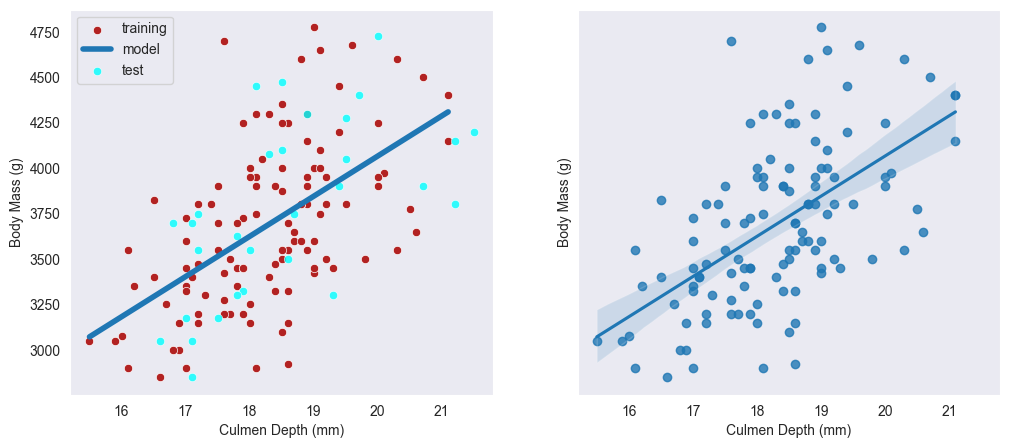

R-Quadrat: 0.3278
R-Quadrat (Test): 0.3501

R-Quadrat Werte für Training:  [-0.03117755  0.18957872  0.37880402  0.26870777  0.4769178 ]


In [43]:
col = 'Culmen Depth (mm)' # gewähltes unabhängiges Merkmal
target = 'Body Mass (g)' # abhängiges Merkmal

penguin_adelie = penguins[penguins['Species'] == 'Adelie']

# 80% der Daten als Trainingsdaten
x_train, x_test, y_train, y_test = train_test_split(penguin_adelie[col], penguin_adelie[target], train_size=0.8)

print('Anzahl Beobachtungen im Trainingsdatensatz: ', x_train.shape[0])
print('Anzahl Beobachtungen im Trainingsdatensatz: ', x_test.shape[0])

var = sm.add_constant(x_train,prepend=True)
model = sm.OLS(y_train, var)
res = model.fit()
display(res.summary())

# Vorhersage basierend auf den Testdaten
# muss die gleiche Struktur (also mit Konstante) haben
pred = res.predict(sm.add_constant(x_test,prepend=True))

# grafische Darstellung
fig, axs = plt.subplots(1,2,figsize=(12,5), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(x=x_train, y=y_train, ax=cax, alpha=1, color='firebrick', label='training')
sea.lineplot(x=x_train, y=res.fittedvalues, ax=cax, label='model', linewidth=4)
sea.scatterplot(x=x_test, y=y_test, ax=cax, alpha=0.8, color='aqua', label='test')
cax.grid()
cax.legend()

# via seaborn regplot: https://seaborn.pydata.org/generated/seaborn.regplot.html
cax = axs[1]
sea.regplot(x=x_train, y=y_train, ax = cax)
cax.grid()
plt.show()

# Lineare Regression in scikit learn
x_train_vec = x_train.values.reshape(-1,1)
y_train_vec =  y_train.values.reshape(-1,1)
reg = LinearRegression().fit(x_train_vec, y_train_vec)
print('R-Quadrat: {0:.4f}'.format(reg.score(x_train_vec, y_train_vec)))
pred = reg.predict(x_test.values.reshape(-1,1))
print('R-Quadrat (Test): {0:.4f}\n'.format(reg.score(x_test.values.reshape(-1,1), y_test.values.reshape(-1,1))))

# Cross-validation
scores = cross_val_score(reg, x_train_vec, y_train_vec, cv=5)
print('R-Quadrat Werte für Training: ', scores)


### Lineare Regression

Einfache Lineare Regression für Body Mass (*abhängige Variable*) basierend auf Flipper Length (*unabhängige Variable*). 

Package: [*statsmodels*](https://www.statsmodels.org/stable/index.html)

Struktur für die lineare Regression ist:

*var = sm.add_constant(x, prepend=True)*

*model = sm.OLS(y, var)*

*res = model.fit()*

[Beispiel mit statsmodels package](https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html)

[Dokumentation der Methode (OLS)](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html#statsmodels.regression.linear_model.OLS)

#### Datenvorbereitung 

Aufteilung in Test- und Trainingsdaten mit [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [34]:
col = 'Flipper Length (mm)' # gewähltes unabhängiges Merkmal
target = 'Body Mass (g)' # abhängiges Merkmal

# 80% der Daten als Trainingsdaten
x_train, x_test, y_train, y_test = train_test_split(penguins[col], penguins[target], train_size=0.8)

print('Anzahl Beobachtungen im Trainingsdatensatz: ', x_train.shape[0])
print('Anzahl Beobachtungen im Trainingsdatensatz: ', x_test.shape[0])

Anzahl Beobachtungen im Trainingsdatensatz:  267
Anzahl Beobachtungen im Trainingsdatensatz:  67


#### Lineare Regression

In [5]:
var = sm.add_constant(x_train,prepend=True)
model = sm.OLS(y_train, var) 
res = model.fit()
display(res.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Body Mass (g)   R-squared:                       0.753
Model:                            OLS   Adj. R-squared:                  0.752
Method:                 Least Squares   F-statistic:                     809.2
Date:                Wed, 29 Oct 2025   Prob (F-statistic):           1.63e-82
Time:                        13:33:44   Log-Likelihood:                -1966.0
No. Observations:                 267   AIC:                             3936.
Df Residuals:                     265   BIC:                             3943.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -5752.7890    349.901    -16.441      0.000   -6441.729   -5063.850
Flipper Length (mm)    49.4908      1.740     28.446      0.000      46.065      52.916
==============================================================================
Omnibus:                        6.686   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.035   Jarque-Bera (JB):                6.483
Skew:                           0.372   Prob(JB):                       0.0391
Kurtosis:                       3.170   Cond. No.                     3.00e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large,  3e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

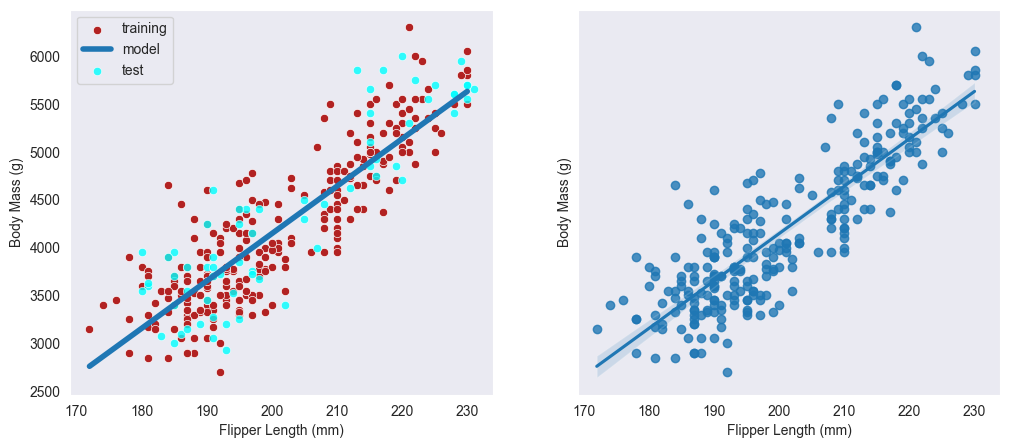

In [6]:
# Vorhersage basierend auf den Testdaten
# muss die gleiche Struktur (also mit Konstante) haben
pred = res.predict(sm.add_constant(x_test,prepend=True))

# grafische Darstellung
fig, axs = plt.subplots(1,2,figsize=(12,5), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(x=x_train, y=y_train, ax=cax, alpha=1, color='firebrick', label='training')
sea.lineplot(x=x_train, y=res.fittedvalues, ax=cax, label='model', linewidth=4)
sea.scatterplot(x=x_test, y=y_test, ax=cax, alpha=0.8, color='aqua', label='test')
cax.grid()
cax.legend()

# via seaborn regplot: https://seaborn.pydata.org/generated/seaborn.regplot.html
cax = axs[1]
sea.regplot(x=x_train, y=y_train, ax = cax)
cax.grid()
plt.show()

In [41]:
for i in range(5):
    # 80% der Daten als Trainingsdaten
    x_train, x_test, y_train, y_test = train_test_split(penguins[col], penguins[target], train_size=0.8, random_state=None)

    # Lineare Regression
    var = sm.add_constant(x_train,prepend=True)
    model = sm.OLS(y_train, var) 
    res = model.fit()
    pred = res.predict(sm.add_constant(x_test,prepend=True))

    # grobe Auswertung
    print('Lauf {0}'.format(i+1))
    print('Quadarierte Abweichung in den Testdaten: {0:.4g}'.format(np.sum((y_test - pred)**2)))
    print('R-Quadrat: {0:.4f}'.format(res.rsquared))
    # Benutzung von r2_score, um Bestimmtheitsmaß für die Testdaten zu bestimmen
    # r2_score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html
    print('R-Quadrat (Test): {0:.4f}\n'.format(r2_score(y_test, pred)))

Lauf 1
Quadarierte Abweichung in den Testdaten: 4.012e+07
R-Quadrat: 0.2137
R-Quadrat (Test): 0.2498

Lauf 2
Quadarierte Abweichung in den Testdaten: 3.481e+07
R-Quadrat: 0.2398
R-Quadrat (Test): 0.1311

Lauf 3
Quadarierte Abweichung in den Testdaten: 3.693e+07
R-Quadrat: 0.2234
R-Quadrat (Test): 0.2234

Lauf 4
Quadarierte Abweichung in den Testdaten: 3.725e+07
R-Quadrat: 0.2412
R-Quadrat (Test): 0.1418

Lauf 5
Quadarierte Abweichung in den Testdaten: 3.572e+07
R-Quadrat: 0.2207
R-Quadrat (Test): 0.0995



In [8]:
# Lineare Regression in scikit learn
x_train_vec = x_train.values.reshape(-1,1)
y_train_vec =  y_train.values.reshape(-1,1)
reg = LinearRegression().fit(x_train_vec, y_train_vec)
print('R-Quadrat: {0:.4f}'.format(reg.score(x_train_vec, y_train_vec)))
pred = reg.predict(x_test.values.reshape(-1,1))
print('R-Quadrat (Test): {0:.4f}\n'.format(reg.score(x_test.values.reshape(-1,1), y_test.values.reshape(-1,1))))

# Cross-validation
scores = cross_val_score(reg, x_train_vec, y_train_vec, cv=5)
print('R-Quadrat Werte für Training: ', scores)

R-Quadrat: 0.7829
R-Quadrat (Test): 0.6252

R-Quadrat Werte für Training:  [0.75224488 0.85123805 0.67302809 0.7555322  0.74287385]


#### Frage

Führe die gleiche einfache lineare Regression durch, aber diesmal pro Pinguinart. Gib an, wieviele Datenpunkte im jeweiligen Trainingsatz sind. 
- Gib es eine Art, für die die lineare Regression "besser" funktioniert als für andere Arten?
- Wieso könnte dies der Fall sein?

In [25]:
col = 'Flipper Length (mm)' # gewähltes unabhängiges Merkmal
target = 'Body Mass (g)' # abhängiges Merkmal

penguin_1 = penguins[penguins['Species'] == 'Adelie']
penguin_2 = penguins[penguins['Species'] == 'Gentoo']
penguin_3 = penguins[penguins['Species'] == 'Chinstrap']

#besser
# for species, data in penguin_1.groupby('Species'):
#     print(species)


# 80% der Daten als Trainingsdaten
x_train_1, x_test_1, y_train_1, y_test_1 = train_test_split(penguin_1[col], penguin_1[target], train_size=0.8)

print('Anzahl Beobachtungen im Trainingsdatensatz 1: ', x_train_1.shape[0])
print('Anzahl Beobachtungen im Trainingsdatensatz 1: ', x_test_1.shape[0])

# 80% der Daten als Trainingsdaten
x_train_2, x_test_2, y_train_2, y_test_2 = train_test_split(penguin_2[col], penguin_2[target], train_size=0.8)

print('Anzahl Beobachtungen im Trainingsdatensatz 2: ', x_train_2.shape[0])
print('Anzahl Beobachtungen im Trainingsdatensatz 3: ', x_test_2.shape[0])


# 80% der Daten als Trainingsdaten
x_train_3, x_test_3, y_train_3, y_test_3 = train_test_split(penguin_3[col], penguin_3[target], train_size=0.8)

print('Anzahl Beobachtungen im Trainingsdatensatz 3: ', x_train_3.shape[0])
print('Anzahl Beobachtungen im Trainingsdatensatz 1: ', x_test_3.shape[0])





Anzahl Beobachtungen im Trainingsdatensatz 1:  116
Anzahl Beobachtungen im Trainingsdatensatz 1:  30
Anzahl Beobachtungen im Trainingsdatensatz 2:  96
Anzahl Beobachtungen im Trainingsdatensatz 3:  24
Anzahl Beobachtungen im Trainingsdatensatz 3:  54
Anzahl Beobachtungen im Trainingsdatensatz 1:  14


In [29]:
# Penguin1
var_1 = sm.add_constant(x_train_1,prepend=True)
model_1 = sm.OLS(y_train_1, var_1)
res_1 = model_1.fit()
display(res_1.summary())

# Penguin2
var_2 = sm.add_constant(x_train_2,prepend=True)
model_2 = sm.OLS(y_train_2, var_2)
res_2 = model_2.fit()
display(res_2.summary())

# Penguin3
var_3 = sm.add_constant(x_train_3,prepend=True)
model_3 = sm.OLS(y_train_3, var_3)
res_3 = model_3.fit()
display(res_3.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Body Mass (g)   R-squared:                       0.197
Model:                            OLS   Adj. R-squared:                  0.190
Method:                 Least Squares   F-statistic:                     28.03
Date:                Wed, 29 Oct 2025   Prob (F-statistic):           5.88e-07
Time:                        14:16:36   Log-Likelihood:                -864.05
No. Observations:                 116   AIC:                             1732.
Df Residuals:                     114   BIC:                             1738.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -2802.5397   1227.224     -2.284      0.024   -5233.662    -371.418
Flipper Length (mm)    34.2069      6.461      5.294      0.000      21.407      47.007
==============================================================================
Omnibus:                        1.524   Durbin-Watson:                   1.895
Prob(Omnibus):                  0.467   Jarque-Bera (JB):                1.471
Skew:                           0.174   Prob(JB):                        0.479
Kurtosis:                       2.572   Cond. No.                     5.99e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.99e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Body Mass (g)   R-squared:                       0.512
Model:                            OLS   Adj. R-squared:                  0.506
Method:                 Least Squares   F-statistic:                     98.49
Date:                Wed, 29 Oct 2025   Prob (F-statistic):           2.66e-16
Time:                        14:16:37   Log-Likelihood:                -698.74
No. Observations:                  96   AIC:                             1401.
Df Residuals:                      94   BIC:                             1407.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -7338.8681   1252.312     -5.860      0.000   -9825.363   -4852.373
Flipper Length (mm)    57.1676      5.760      9.924      0.000      45.730      68.605
==============================================================================
Omnibus:                        9.749   Durbin-Watson:                   2.203
Prob(Omnibus):                  0.008   Jarque-Bera (JB):                9.623
Skew:                           0.720   Prob(JB):                      0.00814
Kurtosis:                       3.577   Cond. No.                     7.53e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.53e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Body Mass (g)   R-squared:                       0.411
Model:                            OLS   Adj. R-squared:                  0.400
Method:                 Least Squares   F-statistic:                     36.27
Date:                Wed, 29 Oct 2025   Prob (F-statistic):           1.77e-07
Time:                        14:16:37   Log-Likelihood:                -386.70
No. Observations:                  54   AIC:                             777.4
Df Residuals:                      52   BIC:                             781.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -4188.2816   1319.077     -3.175      0.003   -6835.203   -1541.360
Flipper Length (mm)    40.4650      6.719      6.023      0.000      26.983      53.947
==============================================================================
Omnibus:                        1.211   Durbin-Watson:                   2.264
Prob(Omnibus):                  0.546   Jarque-Bera (JB):                0.696
Skew:                          -0.266   Prob(JB):                        0.706
Kurtosis:                       3.161   Cond. No.                     5.99e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.99e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

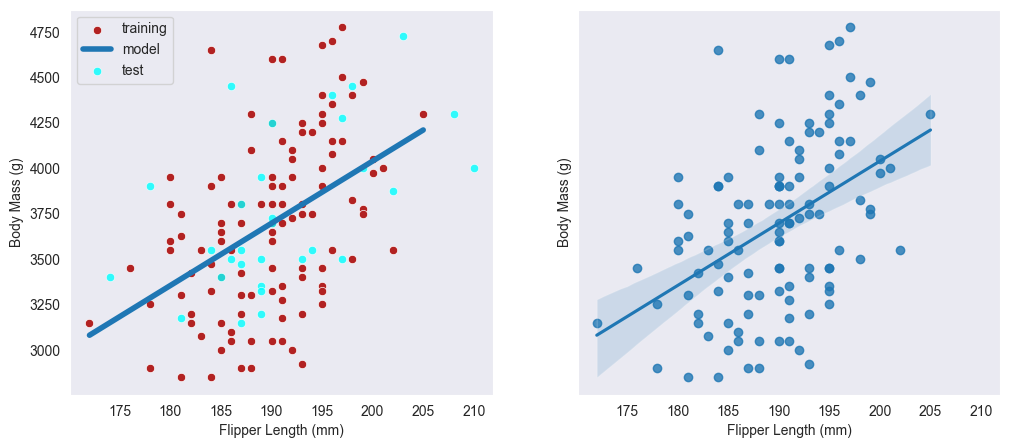

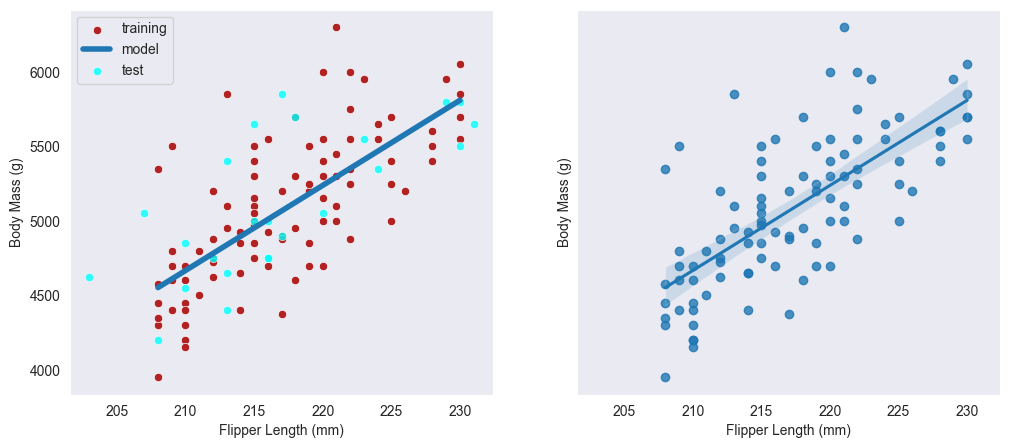

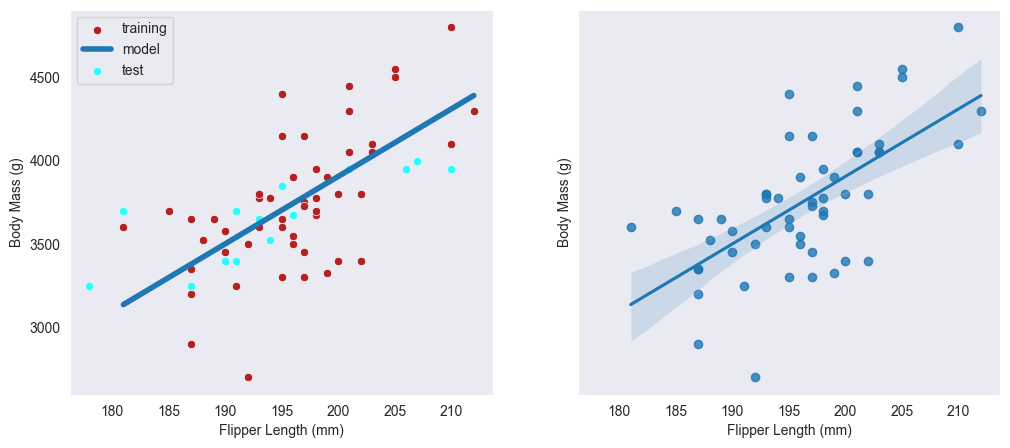

In [30]:
# Penguin 1
# Vorhersage basierend auf den Testdaten
# muss die gleiche Struktur (also mit Konstante) haben
pred_1 = res_1.predict(sm.add_constant(x_test_1,prepend=True))

# grafische Darstellung
fig, axs = plt.subplots(1,2,figsize=(12,5), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(x=x_train_1, y=y_train_1, ax=cax, alpha=1, color='firebrick', label='training')
sea.lineplot(x=x_train_1, y=res_1.fittedvalues, ax=cax, label='model', linewidth=4)
sea.scatterplot(x=x_test_1, y=y_test_1, ax=cax, alpha=0.8, color='aqua', label='test')
cax.grid()
cax.legend()

# via seaborn regplot: https://seaborn.pydata.org/generated/seaborn.regplot.html
cax = axs[1]
sea.regplot(x=x_train_1, y=y_train_1, ax = cax)
cax.grid()
plt.show()

# Penguin 2
# Vorhersage basierend auf den Testdaten
# muss die gleiche Struktur (also mit Konstante) haben
pred_2 = res_2.predict(sm.add_constant(x_test_2,prepend=True))

# grafische Darstellung
fig, axs = plt.subplots(1,2,figsize=(12,5), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(x=x_train_2, y=y_train_2, ax=cax, alpha=1, color='firebrick', label='training')
sea.lineplot(x=x_train_2, y=res_2.fittedvalues, ax=cax, label='model', linewidth=4)
sea.scatterplot(x=x_test_2, y=y_test_2, ax=cax, alpha=0.8, color='aqua', label='test')
cax.grid()
cax.legend()

# via seaborn regplot: https://seaborn.pydata.org/generated/seaborn.regplot.html
cax = axs[1]
sea.regplot(x=x_train_2, y=y_train_2, ax = cax)
cax.grid()
plt.show()

# Penguin 3
# Vorhersage basierend auf den Testdaten
# muss die gleiche Struktur (also mit Konstante) haben
pred_3 = res_3.predict(sm.add_constant(x_test_2,prepend=True))

# grafische Darstellung
fig, axs = plt.subplots(1,2,figsize=(12,5), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(x=x_train_3, y=y_train_3, ax=cax, alpha=1, color='firebrick', label='training')
sea.lineplot(x=x_train_3, y=res_3.fittedvalues, ax=cax, label='model', linewidth=4)
sea.scatterplot(x=x_test_3, y=y_test_3, ax=cax, alpha=0.8, color='aqua', label='test')
cax.grid()
cax.legend()

# via seaborn regplot: https://seaborn.pydata.org/generated/seaborn.regplot.html
cax = axs[1]
sea.regplot(x=x_train_3, y=y_train_3, ax = cax)
cax.grid()
plt.show()

### Visualisierung der Residuen

verschiedene Versionen:
- Streudiagramm der Residuen
- Vergleich der Verteilungen
- q-q Plot


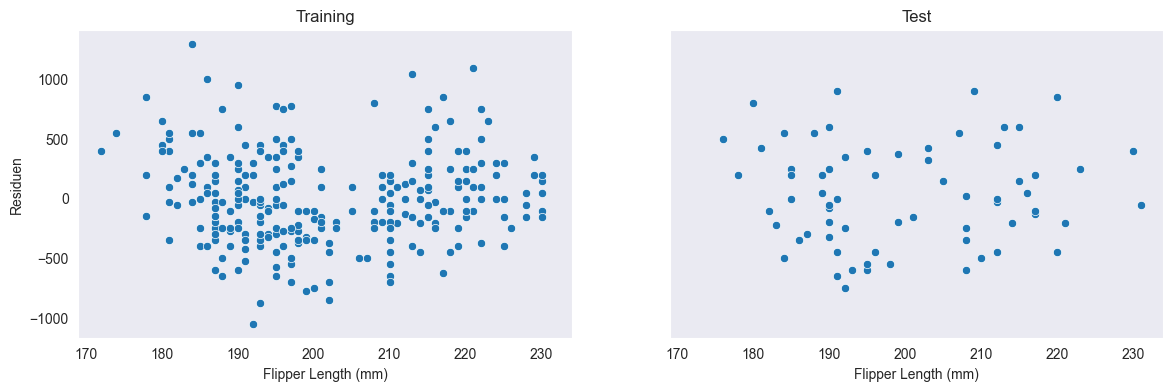

In [33]:
# nochmals die lineare regession
col = 'Flipper Length (mm)' # gewähltes unabhängiges Merkmal
target = 'Body Mass (g)' # abhängiges Merkmal
x_train, x_test, y_train, y_test = train_test_split(penguins[col], penguins[target], train_size=0.8)
var = sm.add_constant(x_train, prepend=True)
model = sm.OLS(y_train, var) 
res = model.fit()
pred = res.predict(sm.add_constant(x_test, prepend=True))

# Streudiagramm
fig, axs = plt.subplots(1, 2, figsize=(14,4), sharex=True, sharey=True)
cax = axs[0]
sea.scatterplot(y=res.resid, x=x_train, ax=cax)
cax.set_title('Training')
cax.set_ylabel('Residuen')
cax.grid()

cax = axs[1]
error = y_test - pred
sea.scatterplot(y=error, x=x_test, ax=cax)
cax.set_title('Test')
cax.grid()

plt.show()

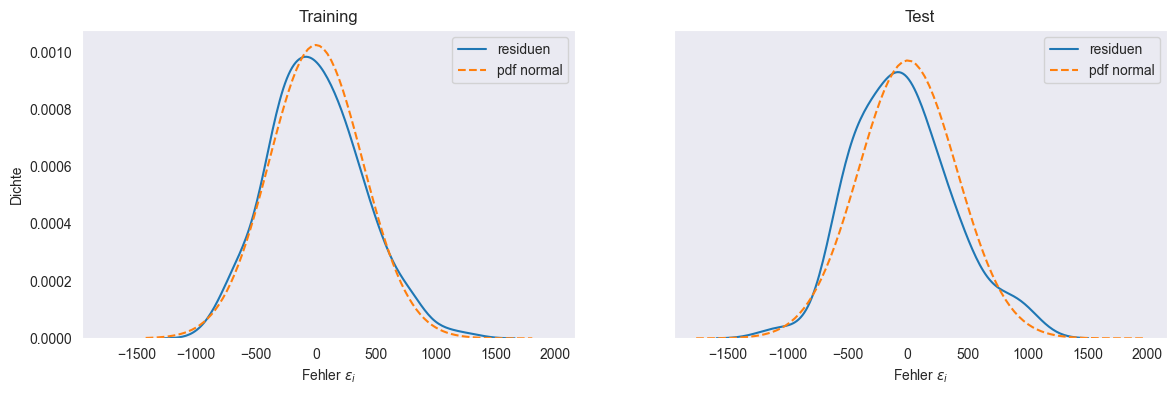

In [10]:
# Fehlerverteilung mittels kde-plot
# kde-plot: https://seaborn.pydata.org/generated/seaborn.kdeplot.html
fig, axs = plt.subplots(1, 2, figsize=(14,4), sharex=True, sharey=True)
cax = axs[0]
sea.kdeplot(res.resid, ax=cax, label='residuen')
# empirische Verteilung durch Normalverteilung approximiert
rv = stats.norm(loc=0, scale=np.std(res.resid, ddof=2))
xmin, xmax = cax.get_xlim()
xx = np.linspace(xmin, xmax, 101)
sea.lineplot(x=xx, y=rv.pdf(xx), linestyle='--', label='pdf normal', ax=cax)
cax.set_xlabel('Fehler $\epsilon_i$')
cax.set_ylabel('Dichte')
cax.set_title('Training')
cax.grid()

cax = axs[1]
error = y_test - pred
sea.kdeplot(error, ax=cax, label='residuen')
# empirische Verteilung durch Normalverteilung approximiert
rv = stats.norm(loc=0, scale=np.std(error, ddof=2))
xmin, xmax = cax.get_xlim()
xx = np.linspace(xmin, xmax, 101)
sea.lineplot(x=xx, y=rv.pdf(xx), linestyle='--', label='pdf normal', ax=cax)
cax.set_xlabel('Fehler $\epsilon_i$')
cax.set_ylabel('Dichte')
cax.set_title('Test')
cax.grid()

plt.show()

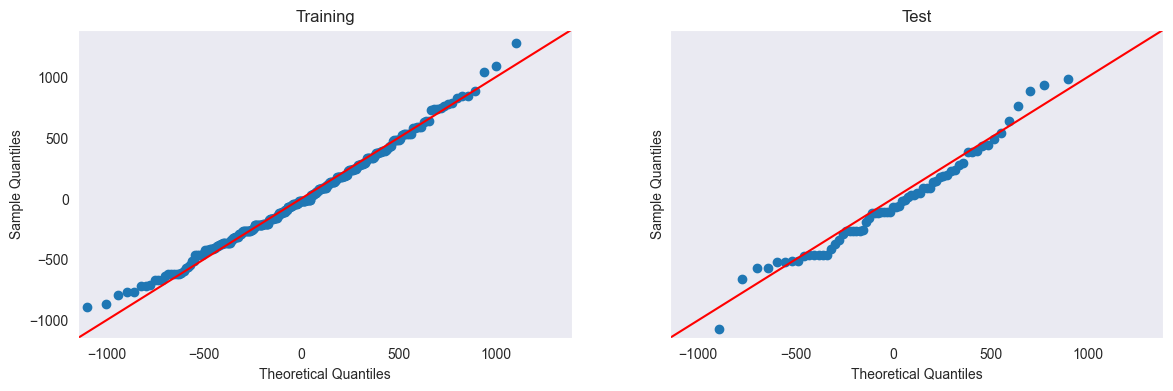

In [11]:
# mittels qq-plot (aus statsmodels)
# qq-plot: https://www.statsmodels.org/stable/generated/statsmodels.graphics.gofplots.qqplot.html
fig, axs = plt.subplots(1, 2, figsize=(14,4), sharex=True, sharey=True)
cax = axs[0]
sm.qqplot(res.resid, rv, line='45', ax=cax)
cax.set_title('Training')
cax.grid()

cax = axs[1]
error = y_test - pred
sm.qqplot(error, rv, line='45', ax=cax)
cax.set_title('Test')
cax.grid()

plt.show()

#### Frage

Führe eine einfache lineare Regression durch, um das Body Mass der Adelie-Pinguine *bestmöglichst* zu bestimmen. Inwieweit unterscheiden sich die Werte des Bestimmtheitsmasses und die Residuen, bei Benutzung der anderen metrischen Merkmale?